In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

import benchmarks
#import eli5
import itertools

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

import seaborn as sns
%matplotlib inline

import time
import random
from numpy.random import default_rng

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions
from xgboost import XGBClassifier
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

rng = np.random.default_rng(seed=42)
np.random.seed(42)

import warnings
warnings.filterwarnings("ignore")

In [2]:
DataDF = pd.read_csv("BCData.csv")

In [3]:
#DataDF.drop("id",axis=1,inplace=True)
DataDF.drop("id",axis=1,inplace=True)
DataDF['diagnosis']=DataDF['diagnosis'].map({'M':1,'B':0})

In [4]:
x=DataDF[['radius_mean','texture_mean','perimeter_mean','area_mean','smoothness_mean','compactness_mean','concavity_mean','concave_points_mean','symmetry_mean','fractal_dimension_mean','radius_se','texture_se','perimeter_se','area_se','smoothness_se','compactness_se','concavity_se','concave_points_se','symmetry_se','fractal_dimension_se','radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave_points_worst','symmetry_worst','fractal_dimension_worst']]
y=DataDF['diagnosis'] 

In [5]:
X=x

In [6]:
X.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [7]:
X

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


# Fitness Function

In [8]:
def fitness_function(position, X, y=None, alpha=0.7):
    """
    Filter-based fitness using variance (relevance) and correlation (redundancy)
    Works with pandas DataFrame X
    """
    selected_idx = np.where(position > 0.5)[0]

    # Penalize empty feature set
    if len(selected_idx) == 0:
        return 1.0

    X_sel = X.iloc[:, selected_idx]

    # -------- Relevance (mean variance) --------
    relevance = X_sel.var(axis=0).mean()

    # -------- Redundancy (mean absolute correlation) --------
    if X_sel.shape[1] > 1:
        corr = X_sel.corr().abs()
        redundancy = corr.values[np.triu_indices_from(corr, k=1)].mean()
    else:
        redundancy = 0.0

    # -------- Normalization --------
    max_var = X.var(axis=0).max()
    relevance = relevance / (max_var + 1e-10)

    fitness = alpha * (1 - relevance) + (1 - alpha) * redundancy
    return fitness


# Whale Optimization Algorithm

In [9]:
def WOA_feature_selection(
    X,
    y=None,
    n_whales=20,
    max_iter=50,
    alpha=0.7,
    verbose=True
):
    """
    Whale Optimization Algorithm for feature selection using pandas DataFrame
    """
    n_features = X.shape[1]
    whales = np.random.rand(n_whales, n_features)

    fitness = np.array([
        fitness_function(w, X, y, alpha) for w in whales
    ])

    best_idx = np.argmin(fitness)
    best_whale = whales[best_idx].copy()
    best_fitness = fitness[best_idx]

    convergence = []

    for t in range(max_iter):
        a = 2 - 2 * t / max_iter

        for i in range(n_whales):
            r1, r2 = np.random.rand(), np.random.rand()
            A = 2 * a * r1 - a
            C = 2 * r2
            p = np.random.rand()

            if p < 0.5:
                if abs(A) < 1:
                    D = np.abs(C * best_whale - whales[i])
                    whales[i] = best_whale - A * D
                else:
                    rand_whale = whales[np.random.randint(n_whales)]
                    D = np.abs(C * rand_whale - whales[i])
                    whales[i] = rand_whale - A * D
            else:
                D = np.abs(best_whale - whales[i])
                l = np.random.uniform(-1, 1)
                whales[i] = (
                    D * np.exp(l) * np.cos(2 * np.pi * l)
                    + best_whale
                )

            whales[i] = np.clip(whales[i], 0, 1)

        fitness = np.array([
            fitness_function(w, X, y, alpha) for w in whales
        ])

        idx = np.argmin(fitness)
        if fitness[idx] < best_fitness:
            best_fitness = fitness[idx]
            best_whale = whales[idx].copy()

        convergence.append(best_fitness)

        if verbose:
            print(f"Iteration {t+1}/{max_iter} | Best Fitness: {best_fitness:.4f}")

    return best_whale, convergence


# Generic Usage (Any Dataset)

In [10]:
#import pandas as pd
## X : pandas DataFrame
## y : optional target vector
#
#best_solution, convergence_curve = WOA_feature_selection(
#    X,
#    y,
#    n_whales=25,
#    max_iter=50,
#    alpha=0.7
#)
#
#selected_features = np.where(best_solution > 0.5)[0]
#
## ✅ Selected feature DataFrame with column names
##Xw = X.iloc[:, selected_features]
#Xw = X[:, selected_features]
#
#Y = y


In [11]:
#if not isinstance(X, pd.DataFrame):
#    X = pd.DataFrame(X, columns=X_columns)
#
## Run WOA feature selection
#best_solution, convergence_curve = WOA_feature_selection(X,y,n_whales=25,max_iter=50,alpha=0.7)
#
#position = np.array([1, 0, 1, 0, 1])
#
## Select features based on WOA output
#selected_features = np.where(best_solution > 0.5)[0]
#
## Optimized feature DataFrame
#Xw = X.iloc[:, selected_features]
#
# Get feature names
#selected_feature_names = Xw.columns.tolist()
#
## Target vector
#Y = y
#
## Optional: print selected feature names
#print("Selected feature indices:", selected_features)
#print("Selected feature names:", Xw.columns.tolist())

In [12]:
#import pandas as pd
#import numpy as np
#
## If X is not a DataFrame, convert it and assign proper column names
#if isinstance(X, np.ndarray):
#    # Make sure X_columns contains actual feature names as strings
#    X = pd.DataFrame(X, columns=X_columns)
#
## Run WOA feature selection
#best_solution, convergence_curve = WOA_feature_selection(X, y, n_whales=25, max_iter=50, alpha=0.7)
#
## Select features based on WOA output
#selected_features_idx = np.where(best_solution > 0.5)[0]

## Check if any features were selected
#if len(selected_features_idx) == 0:
#    raise ValueError("No features were selected by WOA. Try lowering the threshold or adjusting parameters.")
#
## Subset X based on selected features and keep original column names
#Xw = X.iloc[:, selected_features_idx]
#
## Get feature names
#selected_feature_names = Xw.columns.tolist()
#
## Target vector
#Y = y
#
## Print selected features
#print("Selected feature indices:", selected_features_idx)
#print("Selected feature names:", selected_feature_names)


In [39]:
# We pass the DataFrame directly to the function
best_solution, convergence_curve = WOA_feature_selection(x,y,n_whales=60,max_iter=100,alpha=0.7)

# --- 3. Extract Selected Features and Names ---
# WOA returns a continuous vector; we threshold at 0.5 to select features
selected_features_idx = np.where(best_solution > 0.0001)[0]

if len(selected_features_idx) == 0:
    print("Warning: No features selected. Using all features as fallback.")
    Xw = x
    selected_feature_names = x.columns.tolist()
else:
    # Subset the DataFrame using iloc to get the data
    Xw = x.iloc[:, selected_features_idx]
    # Get the actual column names
    selected_feature_names = Xw.columns.tolist()

# --- 4. Results ---
print(f"Number of features selected: {len(selected_feature_names)}")
print("-" * 30)
print("Selected feature names:")
print(selected_feature_names)

# Xw is now your final dataset with only selected features
# selected_feature_names contains the strings of those features

Iteration 1/100 | Best Fitness: 0.6320
Iteration 2/100 | Best Fitness: 0.4047
Iteration 3/100 | Best Fitness: 0.4047
Iteration 4/100 | Best Fitness: 0.4047
Iteration 5/100 | Best Fitness: 0.4047
Iteration 6/100 | Best Fitness: 0.4047
Iteration 7/100 | Best Fitness: 0.4047
Iteration 8/100 | Best Fitness: 0.4047
Iteration 9/100 | Best Fitness: 0.4047
Iteration 10/100 | Best Fitness: 0.4047
Iteration 11/100 | Best Fitness: 0.4047
Iteration 12/100 | Best Fitness: 0.4047
Iteration 13/100 | Best Fitness: 0.4047
Iteration 14/100 | Best Fitness: 0.4047
Iteration 15/100 | Best Fitness: 0.4047
Iteration 16/100 | Best Fitness: 0.4047
Iteration 17/100 | Best Fitness: 0.4047
Iteration 18/100 | Best Fitness: 0.4047
Iteration 19/100 | Best Fitness: 0.4047
Iteration 20/100 | Best Fitness: 0.4047
Iteration 21/100 | Best Fitness: 0.4047
Iteration 22/100 | Best Fitness: 0.4047
Iteration 23/100 | Best Fitness: 0.4047
Iteration 24/100 | Best Fitness: 0.4047
Iteration 25/100 | Best Fitness: 0.4047
Iteration

In [40]:
Xw

,radius_mean,area_mean,compactness_mean,concavity_mean,symmetry_mean,radius_se,area_se,smoothness_se,compactness_se,concavity_se,...,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,symmetry_worst,fractal_dimension_worst
0,17.99,1001.0,0.27760,0.30010,0.2419,1.0950,153.40,0.006399,0.04904,0.05373,...,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.4601,0.11890
1,20.57,1326.0,0.07864,0.08690,0.1812,0.5435,74.08,0.005225,0.01308,0.01860,...,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2750,0.08902
2,19.69,1203.0,0.15990,0.19740,0.2069,0.7456,94.03,0.006150,0.04006,0.03832,...,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.3613,0.08758
3,11.42,386.1,0.28390,0.24140,0.2597,0.4956,27.23,0.009110,0.07458,0.05661,...,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6638,0.17300
4,20.29,1297.0,0.13280,0.19800,0.1809,0.7572,94.44,0.011490,0.02461,0.05688,...,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,1479.0,0.11590,0.24390,0.1726,1.1760,158.70,0.010300,0.02891,0.05198,...,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.2060,0.07115
565,20.13,1261.0,0.10340,0.14400,0.1752,0.7655,99.04,0.005769,0.02423,0.03950,...,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.2572,0.06637
566,16.60,858.1,0.10230,0.09251,0.1590,0.4564,48.55,0.005903,0.03731,0.04730,...,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.2218,0.07820
567,20.60,1265.0,0.27700,0.35140,0.2397,0.7260,86.22,0.006522,0.06158,0.07117,...,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.4087,0.12400


In [41]:
Xw.columns

Index(['radius_mean', 'area_mean', 'compactness_mean', 'concavity_mean',
       'symmetry_mean', 'radius_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [61]:
n=0
m=0.20

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=m, random_state=n)
xw_train, xw_test, y_train, y_test = train_test_split(Xw, y, test_size=m, random_state=n)

In [43]:
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.ensemble import VotingClassifier
clf1 = LogisticRegression(solver='lbfgs',max_iter=100,verbose=3)
clf2 = RandomForestClassifier()
clf3 = DecisionTreeClassifier(criterion='gini',max_depth=8,max_leaf_nodes=7,random_state=40)
#clf = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft')
#clf = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard')


models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    #"HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(xw_train, y_train)
    pred = model.predict(xw_test)
    prob = model.predict_proba(xw_test)[:, 1]
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)
    print(f"{name} -> Accuracy: {acc:.4f}, ROC AUC: {auc:.4f}")

LR -> Accuracy: 0.9474, ROC AUC: 0.9914
RF -> Accuracy: 0.9649, ROC AUC: 0.9938
xGB -> Accuracy: 0.9737, ROC AUC: 0.9946
DT -> Accuracy: 0.9123, ROC AUC: 0.9190
MLP -> Accuracy: 0.8947, ROC AUC: 0.9667


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


SVC -> Accuracy: 0.9649, ROC AUC: 0.9927


In [62]:
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix

models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(hidden_layer_sizes=(200,200,200),activation='logistic',max_iter=300, random_state=0,verbose=False),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}
print
# --- Step 7: Evaluate models ---
for name, model in models.items():
    model.fit(xw_train, y_train)
    pred = model.predict(xw_test)
    acc = accuracy_score(y_test, pred)   
    prec = precision_score(y_test, pred,average='weighted')
    rec = recall_score(y_test, pred,average='weighted')
    f1 = f1_score(y_test, pred,average='weighted')
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    # Print all results in one line
    print(f"{name} -> Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-score: {f1:.4f}, Confusion Matrix: [TP={tp}, FP={fp}, FN={fn}, TN={tn}]")
#    
#    pred = model.predict(xw_test)
#    #prob = model.predict_proba(xw_test)[:, 1]
#    acc = accuracy_score(y_test, pred)
#    #auc = roc_auc_score(y_test, prob)
#    cm = confusion_matrix(y_test, pred).ravel()
#    cm_str = ' '.join(map(str, cm))
##    print(f"{name} -> Accuracy: {acc:.4f},ROC AUC: {auc:.4f}, Confusion Matrix: [{cm_str}]")
#    print(f"{name} -> Accuracy: {acc:.4f}, Confusion Matrix: [{cm_str}]")

LR -> Accuracy: 0.9474, Precision: 0.9503, Recall: 0.9474, F1-score: 0.9476, Confusion Matrix: [TP=46, FP=5, FN=1, TN=62]
RF -> Accuracy: 0.9649, Precision: 0.9657, Recall: 0.9649, F1-score: 0.9650, Confusion Matrix: [TP=46, FP=3, FN=1, TN=64]
xGB -> Accuracy: 0.9737, Precision: 0.9739, Recall: 0.9737, F1-score: 0.9737, Confusion Matrix: [TP=46, FP=2, FN=1, TN=65]
DT -> Accuracy: 0.9298, Precision: 0.9328, Recall: 0.9298, F1-score: 0.9302, Confusion Matrix: [TP=45, FP=6, FN=2, TN=61]
MLP -> Accuracy: 0.9298, Precision: 0.9312, Recall: 0.9298, F1-score: 0.9293, Confusion Matrix: [TP=41, FP=2, FN=6, TN=65]
SVC -> Accuracy: 0.9737, Precision: 0.9739, Recall: 0.9737, F1-score: 0.9737, Confusion Matrix: [TP=46, FP=2, FN=1, TN=65]
HVC -> Accuracy: 0.9561, Precision: 0.9578, Recall: 0.9561, F1-score: 0.9563, Confusion Matrix: [TP=46, FP=4, FN=1, TN=63]


In [45]:
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold

# Define base classifiers for voting
clf1 = LogisticRegression()
clf2 = RandomForestClassifier(n_estimators=200)
clf3 = DecisionTreeClassifier()

# Define models
models = {
    "LR": LogisticRegression(),
    "RF": RandomForestClassifier(n_estimators=200),
    "xGB": XGBClassifier(),
    "DT": DecisionTreeClassifier(),
    "MLP": MLPClassifier(max_iter=100, random_state=0),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft'),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# Use Stratified K-Fold for cross-validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

# Evaluate models
for name, model in models.items():
    # Cross-validated accuracy
    acc_scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    mean_acc = np.mean(acc_scores)
    std_acc = np.std(acc_scores)

    # Cross-validated predictions for confusion matrix
    y_pred = cross_val_predict(model, X, y, cv=cv)
    cm = confusion_matrix(y, y_pred).ravel()
    cm_str = ' '.join(map(str, cm))

    print(f"{name} -> Mean Accuracy: {mean_acc:.4f} ± {std_acc:.4f}, Confusion Matrix: [{cm_str}]")

LR -> Mean Accuracy: 0.9456 ± 0.0183, Confusion Matrix: [343 14 17 195]
RF -> Mean Accuracy: 0.9631 ± 0.0228, Confusion Matrix: [348 9 11 201]
xGB -> Mean Accuracy: 0.9701 ± 0.0209, Confusion Matrix: [352 5 12 200]
DT -> Mean Accuracy: 0.9314 ± 0.0347, Confusion Matrix: [335 22 21 191]
MLP -> Mean Accuracy: 0.9349 ± 0.0369, Confusion Matrix: [344 13 24 188]
SVC -> Mean Accuracy: 0.9631 ± 0.0242, Confusion Matrix: [348 9 15 197]
HVC -> Mean Accuracy: 0.9613 ± 0.0246, Confusion Matrix: [349 8 15 197]


In [46]:
Xw.columns

Index(['radius_mean', 'area_mean', 'compactness_mean', 'concavity_mean',
       'symmetry_mean', 'radius_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [47]:
Xwhale=x[['radius_mean', 'area_mean', 'compactness_mean', 'concavity_mean',
       'symmetry_mean', 'radius_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'symmetry_worst', 'fractal_dimension_worst']]

In [49]:
Xwhale.columns

Index(['radius_mean', 'area_mean', 'compactness_mean', 'concavity_mean',
       'symmetry_mean', 'radius_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [54]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("WOA, Cross Validation") 

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

# --- Define Base Models ---
clf1 = LogisticRegression(max_iter=300, solver='liblinear', fit_intercept=True)
clf2 = RandomForestClassifier(criterion='gini', max_depth=200, random_state=0)
clf3 = DecisionTreeClassifier(criterion='gini', max_depth=12, max_leaf_nodes=10)

# --- Model Dictionary ---
models = {
    "LR": LogisticRegression(max_iter=300, solver='liblinear', fit_intercept=True),
    "RF": RandomForestClassifier(criterion='gini', max_depth=200, random_state=0),
    "xGB": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, verbosity=0, eval_metric="logloss"),
    "DT": DecisionTreeClassifier(criterion='gini', max_depth=12, max_leaf_nodes=10),
    "MLP": MLPClassifier(hidden_layer_sizes=(100,), activation='relu', max_iter=300, random_state=20),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft', weights=[2,3,2]),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

for name, model in models.items():
    #model.fit(x_train, y_train)
    pred = cross_val_predict(model, Xw, y, cv=cv)
    #pred = model.predict(x_test)
    acc = accuracy_score(y, pred)    
    prec = precision_score(y, pred,average='weighted')
    rec = recall_score(y, pred,average='weighted')
    f1 = f1_score(y, pred,average='weighted')
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    # Print all results in one line
    print(f"{name} -> Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-score: {f1:.4f}, Confusion Matrix: [TP={tp}, FP={fp}, FN={fn}, TN={tn}]")


WOA, Cross Validation
LR -> Accuracy: 0.9490, Precision: 0.9489, Recall: 0.9490, F1-score: 0.9489, Confusion Matrix: [TP=195, FP=12, FN=17, TN=345]
RF -> Accuracy: 0.9543, Precision: 0.9543, Recall: 0.9543, F1-score: 0.9542, Confusion Matrix: [TP=196, FP=10, FN=16, TN=347]
xGB -> Accuracy: 0.9701, Precision: 0.9701, Recall: 0.9701, F1-score: 0.9700, Confusion Matrix: [TP=201, FP=6, FN=11, TN=351]
DT -> Accuracy: 0.9244, Precision: 0.9244, Recall: 0.9244, F1-score: 0.9244, Confusion Matrix: [TP=190, FP=21, FN=22, TN=336]
MLP -> Accuracy: 0.9174, Precision: 0.9179, Recall: 0.9174, F1-score: 0.9165, Confusion Matrix: [TP=179, FP=14, FN=33, TN=343]
SVC -> Accuracy: 0.9561, Precision: 0.9562, Recall: 0.9561, F1-score: 0.9559, Confusion Matrix: [TP=195, FP=8, FN=17, TN=349]
HVC -> Accuracy: 0.9561, Precision: 0.9560, Recall: 0.9561, F1-score: 0.9560, Confusion Matrix: [TP=197, FP=10, FN=15, TN=347]


OA, Cross Validation with t-test
WOA, Cross Validation (with Wilcoxon Test)

LR: Mean Accuracy = 0.9526
Fold Accuracies = [0.9825 0.9474 0.9474 0.8772 0.9474 0.9474 0.9649 0.9649 0.9474 1.    ]

RF: Mean Accuracy = 0.9561
Fold Accuracies = [0.9649 0.9825 0.9825 0.8947 0.9649 0.9649 0.9649 0.9298 0.9298 0.9821]

xGB: Mean Accuracy = 0.9614
Fold Accuracies = [0.9649 1.     0.9825 0.8596 0.9649 0.9825 0.9649 0.9649 0.9298 1.    ]

DT: Mean Accuracy = 0.9192
Fold Accuracies = [0.9474 0.9123 0.9298 0.8596 0.8947 0.9123 0.9649 0.8947 0.9123 0.9643]

MLP: Mean Accuracy = 0.9139
Fold Accuracies = [0.9474 0.8772 0.9298 0.807  0.8772 0.9123 0.9123 0.9825 0.9474 0.9464]

SVC: Mean Accuracy = 0.9509
Fold Accuracies = [0.9474 0.9649 0.9474 0.9123 0.9649 0.9474 0.9649 0.9298 0.9298 1.    ]

HVC: Mean Accuracy = 0.9561
Fold Accuracies = [0.9649 0.9825 0.9474 0.9123 0.9649 0.9474 0.9825 0.9298 0.9298 1.    ]

Statistical Significance (Wilcoxon Signed-Rank Test vs LR)
RF: p-value = 0.51132  ⚠️ Not stat

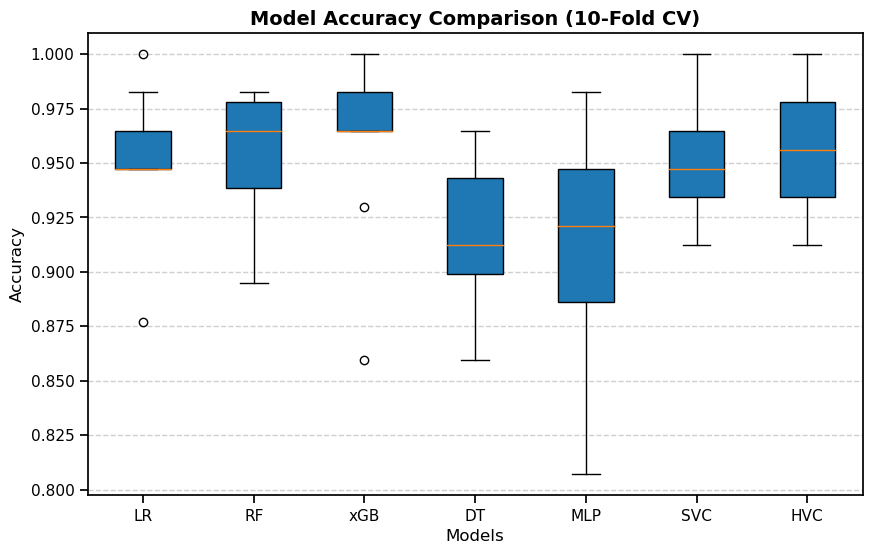

In [55]:
print("\033[WOA, Cross Validation with t-test\033[0m")


from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from scipy.stats import wilcoxon
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

print("\033[1mWOA, Cross Validation (with Wilcoxon Test)\033[0m")

# --- Define Base Models ---
clf1 = LogisticRegression(max_iter=300, solver='liblinear', fit_intercept=True)
clf2 = RandomForestClassifier(criterion='gini', max_depth=200, random_state=0)
clf3 = DecisionTreeClassifier(criterion='gini', max_depth=12, max_leaf_nodes=10)

# --- Model Dictionary ---
models = {
    "LR": LogisticRegression(max_iter=300, solver='liblinear', fit_intercept=True),
    "RF": RandomForestClassifier(criterion='gini', max_depth=200, random_state=0),
    "xGB": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, verbosity=0, eval_metric="logloss"),
    "DT": DecisionTreeClassifier(criterion='gini', max_depth=12, max_leaf_nodes=10),
    "MLP": MLPClassifier(hidden_layer_sizes=(100,), activation='relu', max_iter=300, random_state=20),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft', weights=[2,3,2]),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

# --- 10-fold cross-validation setup ---
from sklearn.model_selection import StratifiedKFold
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# --- Store fold accuracies ---
results = {}

# --- Cross-validate each model ---
for name, model in models.items():
    cv_scores = cross_val_score(model, Xw, y, cv=kfold, scoring='accuracy')
    results[name] = cv_scores

    print(f"\n{name}: Mean Accuracy = {cv_scores.mean():.4f}")
    print(f"Fold Accuracies = {np.round(cv_scores, 4)}")

# --- Wilcoxon signed-rank test (pairwise vs Logistic Regression baseline) ---
baseline = results["LR"]

print("\n\033[1mStatistical Significance (Wilcoxon Signed-Rank Test vs LR)\033[0m")
for name, scores in results.items():
    if name != "LR":
        stat, p_value = wilcoxon(baseline, scores)
        print(f"{name}: p-value = {p_value:.5f}", end="  ")
        if p_value < 0.05:
            print("✅ Statistically significant (p < 0.05)")
        else:
            print("⚠️ Not statistically significant (p ≥ 0.05)")

            
            # --- Boxplot of Model Accuracies ---
plt.figure(figsize=(10, 6))
plt.boxplot(results.values(), labels=results.keys(), patch_artist=True)
plt.title("Model Accuracy Comparison (10-Fold CV)", fontsize=14, weight='bold')
plt.ylabel("Accuracy", fontsize=12)
plt.xlabel("Models", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

In [67]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("WOA, Cross Validation") 

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

# --- Define Base Models ---
clf1 = LogisticRegression(max_iter=300, solver='liblinear', fit_intercept=True)
clf2 = RandomForestClassifier(criterion='gini', max_depth=200, random_state=0)
clf3 = DecisionTreeClassifier(criterion='gini', max_depth=12, max_leaf_nodes=10)

# --- Model Dictionary ---
models = {
    "LR": LogisticRegression(max_iter=300, solver='liblinear', fit_intercept=True),
    "RF": RandomForestClassifier(criterion='gini', max_depth=200, random_state=0),
    "xGB": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, verbosity=0, eval_metric="logloss"),
    "DT": DecisionTreeClassifier(criterion='gini', max_depth=12, max_leaf_nodes=10),
    "MLP": MLPClassifier(hidden_layer_sizes=(100,), activation='relu', max_iter=300, random_state=20),
    "SVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft', weights=[2,3,2]),
    "HVC": VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='hard'),
}

for name, model in models.items():
    #model.fit(x_train, y_train)
    pred = cross_val_predict(model, Xw, y, cv=cv)
    #pred = model.predict(x_test)
    acc = accuracy_score(y, pred)    
    prec = precision_score(y, pred,average='weighted')
    rec = recall_score(y, pred,average='weighted')
    f1 = f1_score(y, pred,average='weighted')
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    # Print all results in one line
    print(f"{name} -> Accuracy: {acc.mean():.4f} ± {acc.std():.4f},, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-score: {f1:.4f}, Confusion Matrix: [TP={tp}, FP={fp}, FN={fn}, TN={tn}]")


WOA, Cross Validation
LR -> Accuracy: 0.9490 ± 0.0000,, Precision: 0.9489, Recall: 0.9490, F1-score: 0.9489, Confusion Matrix: [TP=195, FP=12, FN=17, TN=345]
RF -> Accuracy: 0.9543 ± 0.0000,, Precision: 0.9543, Recall: 0.9543, F1-score: 0.9542, Confusion Matrix: [TP=196, FP=10, FN=16, TN=347]
xGB -> Accuracy: 0.9701 ± 0.0000,, Precision: 0.9701, Recall: 0.9701, F1-score: 0.9700, Confusion Matrix: [TP=201, FP=6, FN=11, TN=351]
DT -> Accuracy: 0.9262 ± 0.0000,, Precision: 0.9261, Recall: 0.9262, F1-score: 0.9261, Confusion Matrix: [TP=190, FP=20, FN=22, TN=337]
MLP -> Accuracy: 0.9174 ± 0.0000,, Precision: 0.9179, Recall: 0.9174, F1-score: 0.9165, Confusion Matrix: [TP=179, FP=14, FN=33, TN=343]
SVC -> Accuracy: 0.9543 ± 0.0000,, Precision: 0.9543, Recall: 0.9543, F1-score: 0.9541, Confusion Matrix: [TP=195, FP=9, FN=17, TN=348]
HVC -> Accuracy: 0.9561 ± 0.0000,, Precision: 0.9560, Recall: 0.9561, F1-score: 0.9560, Confusion Matrix: [TP=197, FP=10, FN=15, TN=347]
